# Lecture 11 — Time-Series Foundation Model finetunen (TimesFM 2.5 + Hugging Face)

In dieser Lecture nehmen wir ein **vortrainiertes Time-Series Foundation Model**
von Google — **TimesFM 2.5 (200M)** — und passen es mit **LoRA** (Parameter-
Efficient Fine-Tuning) an echte Börsendaten an.

**Idee eines Foundation Models für Zeitreihen:** So wie ein Sprachmodell auf
Unmengen Text vortrainiert wird, ist TimesFM auf Milliarden von Zeitreihen-
Punkten vortrainiert. Es kann **zero-shot** forecasten — also Reihen vorhersagen,
die es nie gesehen hat, ohne Training. Wir prüfen, ob ein leichtes Fine-Tuning
auf *unserer* Domäne (Aktienkurse) den Forecast messbar verbessert.

**Was wir tun:**
1. Aktien-Kursdaten aus dem Projekt `trading-agent` laden (adjustierte Schlusskurse).
2. Das Modell **zero-shot** als Baseline forecasten lassen.
3. Mit **LoRA** fine-tunen (nur ~0.6 % der Parameter werden trainiert).
4. **Zero-shot vs. fine-tuned** vergleichen (MAE + Plots).

**Der Hugging-Face-Weg:** TimesFM 2.5 ist als ganz normales `transformers`-Modell
(`TimesFm2_5ModelForPrediction`) verfügbar und unterstützt damit das komplette
HF-Ökosystem inkl. PEFT/LoRA. Der Forward-Pass berechnet den Trainings-Loss
selbst, wenn man `future_values` übergibt — Fine-Tuning ist also ein ganz
normaler PyTorch-Trainingsloop.

> Vorbereitung: einmalig `python prepare_data.py` ausführen, um die Kursreihen
> aus `../../trading-agent` in `data/trading_series.npz` zu cachen.

## 0. Setup & Imports

Wir erkennen automatisch das beste Device. Auf dem Mac ist das **MPS** (Apple
GPU). TimesFM nutzt intern **RevIN** (Instanz-Normalisierung) — wir dürfen die
Daten daher **nicht** selbst normalisieren, sondern füttern die Rohkurse.

In [1]:
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

# --- Device & dtype ------------------------------------------------------
if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.bfloat16
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32   # bf16-Training ist auf MPS unzuverlässig
else:
    DEVICE, DTYPE = "cpu", torch.float32
print("Device:", DEVICE, "| dtype:", DTYPE)

# --- Hyperparameter (für eine Lecture-Demo bewusst klein) ----------------
# Lokaler Modellordner falls vorhanden (per curl gezogen, weil der Xet-Hub-
# Download in dieser Umgebung stockt), sonst direkt von Hugging Face.
_LOCAL = Path("models/timesfm-2.5-200m")
MODEL_ID    = str(_LOCAL) if _LOCAL.exists() else "google/timesfm-2.5-200m-transformers"
CONTEXT_LEN = 256    # Eingabe-Fenster (muss Vielfaches von 32 sein) ~1 Handelsjahr
HORIZON_LEN = 32     # Vorhersage-Horizont ~6 Wochen
NUM_SAMPLES = 1500   # zufällige Trainingsfenster
EPOCHS      = 2
BATCH_SIZE  = 16
LR          = 1e-4
LORA_R      = 4
LORA_ALPHA  = 8
LORA_DROPOUT= 0.05
SEED        = 42
ADAPTER_DIR = "timesfm_trading_lora"

torch.manual_seed(SEED)
np.random.seed(SEED)

Device: mps | dtype: torch.float32


## 1. Daten laden

Die Reihen stammen aus dem Schwester-Projekt `trading-agent`: pro Symbol eine
JSON-Datei mit täglichen OHLCV-Bars. `prepare_data.py` hat daraus die
**adjustierten Schlusskurse** (`adjClose`) extrahiert, aufsteigend in der Zeit.

Wir teilen jede Reihe in einen **Trainingsteil** und einen **Holdout** (die
letzten `HORIZON_LEN` Punkte). Auf dem Holdout messen wir später die
Forecast-Güte — der ist während des Trainings nie sichtbar.

In [2]:
DATA_FILE = Path("data/trading_series.npz")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        "data/trading_series.npz fehlt — bitte zuerst `python prepare_data.py` ausführen."
    )

blob = np.load(DATA_FILE, allow_pickle=True)
series_all = list(blob["series"])
symbols_all = list(blob["symbols"])
print(f"{len(series_all)} Symbole geladen")

# Nur Reihen behalten, die lang genug für Kontext + Horizont sind.
min_len = CONTEXT_LEN + HORIZON_LEN
pairs = [(s, sym) for s, sym in zip(series_all, symbols_all) if len(s) >= min_len]
series = [p[0] for p in pairs]
symbols = [p[1] for p in pairs]
print(f"{len(series)} Symbole mit Länge >= {min_len} (Kontext+Horizont)")

# Train/Holdout-Split: Holdout = letzte HORIZON_LEN Punkte jeder Reihe.
train_series = [s[:-HORIZON_LEN] for s in series]   # für Random-Window-Training
lengths = np.array([len(s) for s in series])
print(f"Reihenlänge: min={lengths.min()} median={int(np.median(lengths))} max={lengths.max()}")

250 Symbole geladen
250 Symbole mit Länge >= 288 (Kontext+Horizont)
Reihenlänge: min=400 median=1239 max=1506


## 2. Datasets: zufällige Fenster

Statt immer dasselbe Fenster zu nehmen, schneiden wir **zufällige
`(Kontext, Horizont)`-Fenster** aus den Reihen (wie bei Chronos-2). Das nutzt
die Daten effizienter. Jedes Fenster hat vollen Kontext (kein Zero-Padding),
damit TimesFMs interne Normalisierung nicht verfälscht wird.

In [3]:
from torch.utils.data import Dataset, DataLoader

class RandomWindowDataset(Dataset):
    '''Zufällige (Kontext, Horizont)-Fenster aus mehreren Reihen.'''
    def __init__(self, series_list, context_len, horizon_len, num_samples, seed=42):
        self.series_list = series_list
        self.context_len = context_len
        self.horizon_len = horizon_len
        rng = np.random.default_rng(seed)
        need = context_len + horizon_len
        valid = [i for i, s in enumerate(series_list) if len(s) >= need]
        if not valid:
            raise ValueError("Keine Reihe lang genug für Kontext+Horizont.")
        self.samples = []
        for _ in range(num_samples):
            idx = int(rng.choice(valid))
            s = series_list[idx]
            start = int(rng.integers(0, len(s) - need + 1))
            self.samples.append((idx, start))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        idx, start = self.samples[i]
        s = self.series_list[idx]
        c = s[start : start + self.context_len]
        t = s[start + self.context_len : start + self.context_len + self.horizon_len]
        return (torch.tensor(c, dtype=torch.float32),
                torch.tensor(t, dtype=torch.float32))

class LastWindowDataset(Dataset):
    '''Validierung: letztes Fenster jeder Reihe.'''
    def __init__(self, series_list, context_len, horizon_len):
        self.items = []
        need = context_len + horizon_len
        for s in series_list:
            if len(s) >= need:
                self.items.append((
                    torch.tensor(s[-need:-horizon_len], dtype=torch.float32),
                    torch.tensor(s[-horizon_len:], dtype=torch.float32),
                ))
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.items[i]

train_ds = RandomWindowDataset(train_series, CONTEXT_LEN, HORIZON_LEN, NUM_SAMPLES, SEED)
val_ds   = LastWindowDataset(train_series, CONTEXT_LEN, HORIZON_LEN)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE)
print(f"Train-Fenster: {len(train_ds)} ({len(train_loader)} Batches) | Val: {len(val_ds)}")

Train-Fenster: 1500 (93 Batches) | Val: 250


## 3. Modell laden & Zero-Shot-Baseline

Wir laden TimesFM 2.5 als `transformers`-Modell. Ohne jedes Training lassen wir
es die Holdout-Horizonte forecasten und messen den **MAE** (mittlerer absoluter
Fehler). Das ist unsere Baseline.

Der Forecast läuft über `model(past_values=...)`; das Feld
`out.mean_predictions` enthält die Punktvorhersage.

In [4]:
from transformers import TimesFm2_5ModelForPrediction

print("Lade Basismodell …")
base_model = TimesFm2_5ModelForPrediction.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE,
)
base_model = base_model.to(DEVICE)
base_model.eval()
print("context_length des Modells:", base_model.config.context_length)
ctx_len = min(CONTEXT_LEN, base_model.config.context_length)

/Users/bertram/Projects/github.com/b3rtram/uas_ml/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Lade Basismodell …


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 6562.31it/s]


context_length des Modells: 16384


In [5]:
@torch.no_grad()
def forecast(model, series_list, context_len, horizon_len, device, batch_size=32):
    '''Forecast für den Holdout: nimm die letzten `context_len` Punkte vor dem
    Holdout, sage `horizon_len` voraus. Gibt (preds, truths) als Arrays.'''
    preds, truths = [], []
    need = context_len + horizon_len
    items = [s for s in series_list if len(s) >= need]
    for i in range(0, len(items), batch_size):
        batch = items[i:i+batch_size]
        ctx = torch.stack([
            torch.tensor(s[-need:-horizon_len], dtype=torch.float32) for s in batch
        ]).to(device)
        out = model(past_values=ctx)
        p = out.mean_predictions[:, :horizon_len].float().cpu().numpy()
        for j, s in enumerate(batch):
            preds.append(p[j])
            truths.append(s[-horizon_len:])
    return np.array(preds), np.array(truths)

def metrics(preds, truths):
    '''Mehrere Fehlermaße. mean_mae wird von teuren Aktien dominiert; robust
    sind median_mae und sMAPE (skalenfrei).'''
    ae = np.abs(preds - truths)
    mean_mae = float(ae.mean())
    median_mae = float(np.median(ae.mean(axis=1)))           # pro Symbol, dann Median
    smape = float((2 * ae / np.maximum(np.abs(preds) + np.abs(truths), 1e-6)).mean() * 100)
    return {"mean_mae": mean_mae, "median_mae": median_mae, "smape": smape}

t0 = time.time()
base_preds, truths = forecast(base_model, series, ctx_len, HORIZON_LEN, DEVICE)
base_m = metrics(base_preds, truths)
print(f"Zero-Shot über {len(truths)} Symbole ({time.time()-t0:.1f}s):")
print(f"  mean-MAE={base_m['mean_mae']:.3f}  median-MAE={base_m['median_mae']:.3f}  "
      f"sMAPE={base_m['smape']:.2f}%")

Zero-Shot über 250 Symbole (36.6s):
  mean-MAE=49.235  median-MAE=0.939  sMAPE=10.35%


## 4. LoRA-Fine-Tuning

**LoRA** (Low-Rank Adaptation) friert die Originalgewichte ein und lernt nur
kleine Low-Rank-Zusatzmatrizen. Mit `target_modules="all-linear"` und `r=4`
werden nur ~0.6 % der Parameter trainiert — das reicht oft, um das Modell an
eine neue Domäne anzupassen, und passt locker auf MPS.

In [6]:
from peft import LoraConfig, get_peft_model

ft_model = TimesFm2_5ModelForPrediction.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE,
)
ft_model = ft_model.to(DEVICE)
lora_config = LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, target_modules="all-linear",
    lora_dropout=LORA_DROPOUT, bias="none",
)
ft_model = get_peft_model(ft_model, lora_config)
ft_model.print_trainable_parameters()

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 6505.95it/s]


trainable params: 1,382,912 || all params: 232,672,192 || trainable%: 0.5944


In [ ]:
optimizer = torch.optim.AdamW(ft_model.parameters(), lr=LR, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS * len(train_loader)
)

best_val = float("inf")
for epoch in range(1, EPOCHS + 1):
    ft_model.train()
    running, n = 0.0, 0
    t0 = time.time()
    for context, target in train_loader:
        context = context.to(DEVICE)
        target = target.to(DEVICE)
        out = ft_model(past_values=context, future_values=target,
                       forecast_context_len=ctx_len)
        loss = out.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)
        optimizer.step(); optimizer.zero_grad(); scheduler.step()
        running += loss.item(); n += 1
        if n % 20 == 0:
            print(f"  epoch {epoch} step {n}/{len(train_loader)} "
                  f"train_loss={running/n:.4f}")
    train_loss = running / max(n, 1)

    # Validierung
    ft_model.eval(); vrun, vn = 0.0, 0
    with torch.no_grad():
        for context, target in val_loader:
            out = ft_model(past_values=context.to(DEVICE),
                           future_values=target.to(DEVICE),
                           forecast_context_len=ctx_len)
            vrun += out.loss.item(); vn += 1
    val_loss = vrun / max(vn, 1)
    print(f"Epoch {epoch}/{EPOCHS}  train={train_loss:.4f}  val={val_loss:.4f}  "
          f"({time.time()-t0:.0f}s)")
    if val_loss < best_val:
        best_val = val_loss
        ft_model.save_pretrained(ADAPTER_DIR)
        print(f"  ✓ bester Adapter gespeichert -> {ADAPTER_DIR}")

print(f"Training fertig. Bester Val-Loss: {best_val:.4f}")

  epoch 1 step 20/93 train_loss=1.3989
  epoch 1 step 40/93 train_loss=1.4794
  epoch 1 step 60/93 train_loss=1.4881
  epoch 1 step 80/93 train_loss=1.4486
Epoch 1/2  train=1.4562  val=1.0726  (17s)
  ✓ bester Adapter gespeichert -> timesfm_trading_lora
  epoch 2 step 20/93 train_loss=1.2969
  epoch 2 step 40/93 train_loss=1.4759
  epoch 2 step 60/93 train_loss=1.3421
  epoch 2 step 80/93 train_loss=1.3994
Epoch 2/2  train=1.3710  val=1.0585  (13s)
  ✓ bester Adapter gespeichert -> timesfm_trading_lora
Training fertig. Bester Val-Loss: 1.0585


: 

## 5. Evaluation: Zero-Shot vs. Fine-Tuned

Wir forecasten denselben Holdout mit dem fine-getunten Modell und vergleichen
**mehrere Metriken** mit der Baseline:

- **mean-MAE** — mittlerer absoluter Fehler über *alle* Symbole. ⚠️ Wird von
  teuren Aktien dominiert (ein Fehler von $5 bei einer $500-Aktie zählt genauso
  wie der ganze Kurs einer $5-Aktie). Als alleinige Kennzahl irreführend.
- **median-MAE** — Median des Pro-Symbol-MAE. Robust gegen einzelne Ausreißer.
- **sMAPE** — symmetrischer prozentualer Fehler, **skalenfrei** und damit über
  unterschiedlich teure Aktien vergleichbar.

> Lehrpunkt: Je nach Metrik kann dasselbe Ergebnis „besser" *oder* „schlechter"
> aussehen. Bei heterogenen Skalen ist eine skalenfreie Metrik (sMAPE) Pflicht.

In [8]:
ft_model.eval()
t0 = time.time()
ft_preds, _ = forecast(ft_model, series, ctx_len, HORIZON_LEN, DEVICE)
ft_m = metrics(ft_preds, truths)
print(f"Fine-Tuned-Forecast in {time.time()-t0:.1f}s\n")

def _delta(a, b):  # positive % = Fine-Tuning besser (Fehler kleiner)
    return (a - b) / a * 100

print(f"{'Metrik':<12}{'Zero-Shot':>12}{'Fine-Tuned':>12}{'Δ (besser=+)':>14}")
for key, label in [("mean_mae","mean-MAE"),("median_mae","median-MAE"),("smape","sMAPE")]:
    b, f = base_m[key], ft_m[key]
    print(f"{label:<12}{b:>12.3f}{f:>12.3f}{_delta(b, f):>13.1f}%")

Fine-Tuned-Forecast in 40.6s

Metrik         Zero-Shot  Fine-Tuned  Δ (besser=+)
mean-MAE          49.235      58.685        -19.2%
median-MAE         0.939       0.943         -0.4%
sMAPE             10.353      12.164        -17.5%


### Pro-Symbol-Vergleich & Beispiel-Plot

Links: **sMAPE** (skalenfrei) über alle Holdout-Symbole. Rechts: ein konkretes
Symbol — Kontext (Historie), wahre Zukunft, Zero-Shot- und Fine-Tuned-Forecast.

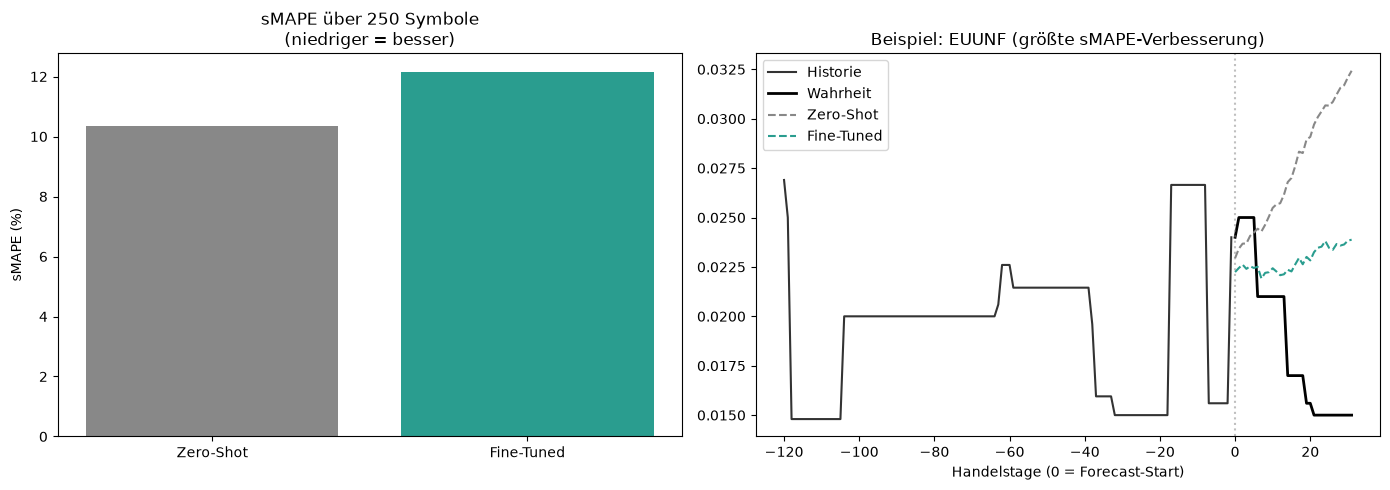

Symbole mit besserem sMAPE nach Fine-Tuning: 127/250


In [9]:
# Pro-Symbol-sMAPE (skalenfrei) für fairen Vergleich
def smape_per_symbol(P):
    ae = np.abs(P - truths)
    return (2 * ae / np.maximum(np.abs(P) + np.abs(truths), 1e-6)).mean(axis=1) * 100

sm_base = smape_per_symbol(base_preds)
sm_ft   = smape_per_symbol(ft_preds)
gain = sm_base - sm_ft                       # >0 = Fine-Tuning besser
ex = int(np.argmax(gain))                    # größte sMAPE-Verbesserung

valid_series = [s for s in series if len(s) >= ctx_len + HORIZON_LEN]
valid_syms   = [sym for s, sym in zip(series, symbols) if len(s) >= ctx_len + HORIZON_LEN]
s = valid_series[ex]
hist_tail = s[-(ctx_len + HORIZON_LEN):-HORIZON_LEN]
ctx_plot = hist_tail[-120:]            # nur die letzten 120 Tage zur Lesbarkeit
x_fut  = np.arange(0, HORIZON_LEN)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5))

axL.bar(["Zero-Shot", "Fine-Tuned"], [base_m["smape"], ft_m["smape"]],
        color=["#888", "#2a9d8f"])
axL.set_title(f"sMAPE über {len(truths)} Symbole\n(niedriger = besser)")
axL.set_ylabel("sMAPE (%)")

axR.plot(np.arange(-len(ctx_plot), 0), ctx_plot, color="#333", label="Historie")
axR.plot(x_fut, truths[ex], color="black", lw=2, label="Wahrheit")
axR.plot(x_fut, base_preds[ex], "--", color="#888", label="Zero-Shot")
axR.plot(x_fut, ft_preds[ex], "--", color="#2a9d8f", label="Fine-Tuned")
axR.axvline(0, color="gray", ls=":", alpha=0.5)
axR.set_title(f"Beispiel: {valid_syms[ex]} (größte sMAPE-Verbesserung)")
axR.set_xlabel("Handelstage (0 = Forecast-Start)")
axR.legend()
plt.tight_layout()
plt.show()

print(f"Symbole mit besserem sMAPE nach Fine-Tuning: {(gain > 0).sum()}/{len(gain)}")

## 6. Zusammenfassung

**Mechanik (funktioniert):**
- **TimesFM 2.5** ist ein vortrainiertes Foundation Model für Zeitreihen und
  forecastet **zero-shot** ohne Training.
- Über `transformers` + **PEFT/LoRA** lässt es sich mit einem normalen PyTorch-
  Loop fine-tunen — nur ~0.6 % der Parameter werden gelernt, der Trainings-Loss
  sinkt sauber, der Adapter wird gespeichert.

**Ergebnis (ehrlich):**
- Das leichte Fine-Tuning hat die Prognose hier **nicht spürbar verbessert** —
  über robuste Metriken (median-MAE, sMAPE) ist es ~neutral bis minimal
  schlechter. Das ist ein realistisches und lehrreiches Ergebnis, kein Fehler:
  1. **Aktienkurse sind nahezu ein Random Walk** — es gibt wenig lernbare
     Struktur, die ein bereits starkes Foundation Model nicht schon kennt.
  2. **Foundation-Modelle sind zero-shot bereits sehr gut kalibriert** — naives
     Fine-Tuning kann sie sogar leicht verschlechtern.
  3. **Die Metrikwahl entscheidet über das Vorzeichen**: der mean-MAE wird von
     wenigen teuren Aktien dominiert; skalenfreie Metriken zeichnen ein anderes
     Bild. → Immer eine robuste, skalenfreie Metrik wählen.

**Zum Experimentieren:**
- Niedrigere `LR` (z.B. `5e-5`), mehr `NUM_SAMPLES`/`EPOCHS`, höheres `LORA_R`.
- Nur auf liquide Aktien einer Branche fine-tunen (homogenere Skala).
- Ziel auf **Log-Returns** statt Preis umstellen (stationärer).
- `CONTEXT_LEN` / `HORIZON_LEN` variieren (Kontext = Vielfaches von 32).

> ⚠️ **Hinweis:** Zweck dieser Lecture ist die **Fine-Tuning-Mechanik** eines
> Foundation Models und der **kritische Umgang mit Metriken**, nicht eine
> profitable Handelsstrategie.